::: {.sb-lesson-links}
[Exercises →](../exercises/house-prices.ipynb)
[Quiz →](../quiz/quiz.qmd)
[All files of this section (zip)](../../files/03-pca.zip)
:::

::: {.sb-downloads}
[Download this notebook](../downloads/lesson-pca.ipynb){download="lesson-pca.ipynb"}
:::

When a dataset has many variables, a lot of them often tell the same story. **PCA** (*Principal Component Analysis*) finds new axes along which the data varies the most, so that a few of them keep most of the information. This lesson builds PCA step by step on small examples, then checks that scikit-learn gives the same result.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from sklearn.datasets import load_digits, load_iris
from sklearn.decomposition import PCA

# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

## Why reduce the number of dimensions?

More variables do not always mean a better analysis. Reducing the number of dimensions helps to:

* **Visualise.** We can draw 2 or 3 variables, not 10 or 64. A good 2D summary of the data shows groups, trends and outliers.
* **Remove redundancy.** Variables are often correlated: *hours of sleep* and a *tiredness score* describe almost the same thing. Keeping both adds little information.
* **Remove noise.** Small random variations spread over many directions. Dropping the directions that carry almost nothing removes part of the noise (you will see it on images in the exercises).
* **Go faster.** A model trained on 20 variables instead of 200 trains faster and needs less memory, often with almost the same performance.

![Left: a flat cloud of points in 3D with three groups that overlap on the screen. Right: the same points in the plane of the first two principal components, where the three groups are clearly separated.](../img/pca_3d_to_2d.png)

Here the 3D cloud is almost flat: two well-chosen axes (PC1 and PC2) keep 99% of its variance, and the three groups become easy to see.

#### See it with data 🔬: correlated variables

The iris dataset measures 4 lengths on 150 flowers. Let's look at their correlations.

In [ ]:
iris = load_iris(as_frame=True).frame.drop(columns="target")
iris.corr().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.00,-0.12,0.87,0.82
sepal width (cm),-0.12,1.00,-0.43,-0.37
petal length (cm),0.87,-0.43,1.00,0.96
petal width (cm),0.82,-0.37,0.96,1.00


**What this shows:** the petal length and the petal width have a correlation of 0.96, and the petal length and the sepal length 0.87. These three columns mostly say "this flower is big" or "this flower is small". The table has 4 columns, but less than 4 independent pieces of information. PCA will find this out on its own.

## Variance and covariance

PCA is all about **variance**, so let's recall two definitions. For $n$ observations of the variables $x$ and $y$, with means $\bar x$ and $\bar y$:

$$\text{Var}(x)=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar x)^2 \qquad\qquad \text{Cov}(x,y)=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar x)(y_i-\bar y)$$

* The **variance** measures how spread out a variable is. In PCA, spread = information: a variable that is the same for everyone tells us nothing about the differences between observations.
* The **covariance** measures how two variables vary *together*. Positive: when $x$ is above its mean, $y$ tends to be above its mean too. Negative: the opposite. Close to 0: no linear link.

With $p$ variables, we put all the variances and covariances in a $p \times p$ table, the **covariance matrix** $C$: the variances on the diagonal, the covariances everywhere else. It is symmetric, because $\text{Cov}(x,y)=\text{Cov}(y,x)$.

#### See it with data 🔬: a covariance matrix by hand

5 students, a maths grade and a physics grade. We compute every term of the formulas.

In [ ]:
grades = pd.DataFrame({"maths": [6, 9, 12, 14, 19], "physics": [8, 9, 13, 12, 18]})
n = len(grades)
dev = grades - grades.mean()                       # deviations from the mean
grades.assign(maths_dev=dev["maths"], physics_dev=dev["physics"],
              maths_dev_squared=dev["maths"] ** 2, physics_dev_squared=dev["physics"] ** 2,
              product=dev["maths"] * dev["physics"])

,maths,physics,maths_dev,physics_dev,maths_dev_squared,physics_dev_squared,product
0,6,8,-6.0,-4.0,36.0,16.0,24.0
1,9,9,-3.0,-3.0,9.0,9.0,9.0
2,12,13,0.0,1.0,0.0,1.0,0.0
3,14,12,2.0,0.0,4.0,0.0,0.0
4,19,18,7.0,6.0,49.0,36.0,42.0


In [ ]:
var_maths = (dev["maths"] ** 2).sum() / (n - 1)
var_physics = (dev["physics"] ** 2).sum() / (n - 1)
cov = (dev["maths"] * dev["physics"]).sum() / (n - 1)
C_hand = np.array([[var_maths, cov], [cov, var_physics]])

print("By hand:\n", C_hand)
print("numpy (np.cov):\n", np.cov(grades, rowvar=False))     # rowvar=False: the variables are the columns

By hand:
 [[24.5  18.75]
 [18.75 15.5 ]]
numpy (np.cov):
 [[24.5  18.75]
 [18.75 15.5 ]]


**What this shows:** both means are 12. The squared deviations of maths add up to 98, so $\text{Var}(\text{maths}) = 98/4 = 24.5$; for physics $62/4 = 15.5$. The products add up to 75, so $\text{Cov} = 75/4 = 18.75$: positive, a student good in maths tends to be good in physics. `np.cov` gives exactly the same matrix.

The covariance depends on the units. Dividing it by the two standard deviations gives the **correlation**, between −1 and 1: here $18.75/\sqrt{24.5 \times 15.5} = 0.96$.

#### See it with data 🔬: what the covariance looks like

Three clouds of 200 points, drawn with variances close to 4 for both variables but with different covariances.

In [ ]:
rng = np.random.default_rng(1)
clouds = [rng.multivariate_normal([0, 0], [[4, c], [c, 4]], size=200) for c in [3, 0, -3]]
covs = [np.cov(pts, rowvar=False) for pts in clouds]
fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.06,
                    subplot_titles=[f"Cov = {C[0, 1]:.2f} (variances {C[0, 0]:.2f}, {C[1, 1]:.2f})" for C in covs])
for k, pts in enumerate(clouds):
    fig.add_trace(go.Scatter(x=pts[:, 0], y=pts[:, 1], mode="markers", showlegend=False,
                             marker=dict(size=5, color=["#3B47C4", "#999999", "#E4572E"][k])), row=1, col=k + 1)
fig.update_xaxes(range=[-7, 7], title_text="x")
fig.update_yaxes(range=[-7, 7])
fig.update_layout(height=380, title="Positive, zero and negative covariance")
fig.show()

**What this shows:** with a covariance of 2.52 the cloud is a tilted ellipse going up; with −3.04 it goes down; with 0.21 it is almost round. The variances only tell the width of the cloud along each axis; the covariance tells how much it is **tilted**. A tilted cloud means redundant variables, and that is what PCA exploits.

## The idea of PCA, step by step



::: {.callout-tip title="Intuition"}
Shine a light on a cloud of points and look at its shadow on a wall. Turn the wall: in some positions the shadow is squeezed and the points pile up; in one position the shadow is as wide as possible. That position keeps the most information about how the points differ. Its direction is the **first principal component**.
:::



Let's do it on 150 students with a maths and a physics grade (simulated, strongly correlated).

In [ ]:
rng = np.random.default_rng(0)
X = rng.multivariate_normal([11, 10], [[6, 4], [4, 4.5]], size=150)    # columns: maths, physics
mean = X.mean(axis=0)
Xc = X - mean                                                           # step 1: centre the data

print("Means before centring:", mean.round(2), "  after:", Xc.mean(axis=0).round(2) + 0.0)   # + 0.0 turns -0.0 into 0.0

Means before centring: [11.32 10.4 ]   after: [0. 0.]


### Step 1: centre the data

We subtract the mean of each variable. The cloud does not change shape; it just moves so that its centre is at $(0, 0)$. All the axes we try next go through this centre.

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=["Raw grades", "Centred grades"])
fig.add_trace(go.Scatter(x=X[:, 0], y=X[:, 1], mode="markers", showlegend=False, marker=dict(size=6)), row=1, col=1)
fig.add_trace(go.Scatter(x=Xc[:, 0], y=Xc[:, 1], mode="markers", showlegend=False, marker=dict(size=6)), row=1, col=2)
fig.add_trace(go.Scatter(x=[mean[0]], y=[mean[1]], mode="markers", name="mean", marker=dict(size=14, symbol="x", color="#E4572E")), row=1, col=1)
fig.add_trace(go.Scatter(x=[0], y=[0], mode="markers", showlegend=False, marker=dict(size=14, symbol="x", color="#E4572E")), row=1, col=2)
fig.update_xaxes(title_text="maths")
fig.update_yaxes(title_text="physics", row=1, col=1)
fig.update_yaxes(scaleanchor="x", row=1, col=1)
fig.update_yaxes(scaleanchor="x2", row=1, col=2)
fig.update_layout(height=400)
fig.show()

### Step 2: project the points on an axis

Take an axis through the centre, at an angle $\theta$. Its direction is the unit vector $u=(\cos\theta, \sin\theta)$. The **projection** of a point $x_i$ on this axis is its "shadow" on the axis. Its position along the axis is a single number:

$$z_i = x_i \cdot u = x_{i1}\cos\theta + x_{i2}\sin\theta$$

With this one number per student, we replace 2 variables by 1. Move the slider to turn the axis: the title gives the **variance of the projections** $z_1, \dots, z_n$.

In [ ]:
angles = np.arange(0, 180, 15)
fig = go.Figure(go.Scatter(x=Xc[:, 0], y=Xc[:, 1], mode="markers", name="students", marker=dict(size=6, color="#999999")))
titles = []
for a in angles:
    u = np.array([np.cos(np.radians(a)), np.sin(np.radians(a))])
    z = Xc @ u                                     # position of each shadow along the axis
    P = np.outer(z, u)                             # the shadows, drawn in the plane
    seg_x = np.column_stack([Xc[:, 0], P[:, 0], np.full(len(z), np.nan)]).ravel()
    seg_y = np.column_stack([Xc[:, 1], P[:, 1], np.full(len(z), np.nan)]).ravel()
    visible = bool(a == angles[0])
    fig.add_trace(go.Scatter(x=[-12 * u[0], 12 * u[0]], y=[-12 * u[1], 12 * u[1]], mode="lines", name="axis",
                             line=dict(color="#111111", width=2), visible=visible))
    fig.add_trace(go.Scatter(x=seg_x, y=seg_y, mode="lines", name="distance to the axis",
                             line=dict(color="#E4572E", width=1), visible=visible))
    fig.add_trace(go.Scatter(x=P[:, 0], y=P[:, 1], mode="markers", name="projections",
                             marker=dict(size=5, color="#3B47C4"), visible=visible))
    titles.append(f"Axis at {a}°: variance of the projections = {z.var(ddof=1):.2f}")

steps = []
for k, a in enumerate(angles):
    visible = [True] + [k == j for j in range(len(angles)) for _ in range(3)]
    steps.append(dict(method="update", label=f"{a}°", args=[{"visible": visible}, {"title.text": titles[k]}]))
fig.update_layout(title=titles[0], height=560, sliders=[dict(steps=steps, currentvalue=dict(prefix="angle: "))],
                  xaxis=dict(range=[-10, 10], title="maths (centred)"),
                  yaxis=dict(range=[-8, 8], title="physics (centred)", scaleanchor="x"))
fig.show()

### Step 3: find the angle with the largest variance

Instead of moving the slider, let's compute the variance of the projections for every angle between 0° and 180°, every half degree.

In [ ]:
theta = np.arange(0, 180, 0.5)
U = np.column_stack([np.cos(np.radians(theta)), np.sin(np.radians(theta))])   # one unit vector per angle
proj_var = (Xc @ U.T).var(axis=0, ddof=1)                                       # variance of the projections
total_var = Xc.var(axis=0, ddof=1).sum()                                        # Var(maths) + Var(physics)

best = theta[proj_var.argmax()]
worst = theta[proj_var.argmin()]
print(f"Total variance: {total_var:.2f}")
print(f"Largest variance of the projections:  {proj_var.max():.2f} at {best}°")
print(f"Smallest variance of the projections: {proj_var.min():.2f} at {worst}°")

Total variance: 10.75
Largest variance of the projections:  9.56 at 36.5°
Smallest variance of the projections: 1.19 at 126.5°


In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=theta, y=proj_var, name="variance of the projections (kept)"))
fig.add_trace(go.Scatter(x=theta, y=total_var - proj_var, name="squared distances to the axis (lost)"))
fig.add_vline(x=best, line_dash="dash", annotation_text=f"PC1: {best}°")
fig.add_vline(x=worst, line_dash="dot", annotation_text=f"PC2: {worst}°")
fig.update_layout(title="Variance of the projections for every angle of the axis", xaxis_title="angle θ of the axis (degrees)",
                  yaxis_title="variance", height=420)
fig.show()

**What this shows:** the total variance of the two grades is 10.75. Projected on the best axis, at 36.5°, the students still have a variance of 9.56: one number keeps most of the spread. The worst axis, at 126.5°, keeps only 1.19. It is exactly perpendicular to the best one (90° more).

The two curves always add up to the total variance (it is Pythagoras: each point is split into its shadow and its distance to the axis). So **the axis that keeps the most variance is also the axis closest to the points**. Both views give the same PCA.

* **PC1** is the axis with the largest variance.
* **PC2** is the axis with the largest variance among the axes perpendicular to PC1. In 2D there is only one choice.
* With $p$ variables, we continue: each new component is perpendicular to all the previous ones and takes the largest variance left. We get $p$ components, sorted from the most to the least important.

## Behind the scenes: eigenvectors of the covariance matrix

Trying every angle works in 2D. With 30 variables there are far too many directions to try. Fortunately, linear algebra gives the answer directly.

For a unit vector $u$, the projections are $z = X_c\,u$ and their variance can be written with the covariance matrix:

$$\text{Var}(z)=\frac{1}{n-1}(X_c u)^\top(X_c u) = u^\top \Big(\frac{1}{n-1}X_c^\top X_c\Big)u = u^\top C\,u$$

The best directions are the **eigenvectors** of $C$: the vectors $u$ such that

$$C\,u=\lambda\,u$$

The number $\lambda$ is the **eigenvalue** of $u$. Multiply the equation by $u^\top$: $u^\top C u = \lambda\,u^\top u = \lambda$. **The eigenvalue is the variance of the data along its eigenvector.** The eigenvector with the largest eigenvalue is PC1, the next one PC2, and so on.



::: {.callout-tip title="Intuition"}
Multiply a vector by a matrix: in general the vector turns and changes length. An **eigenvector** is a special direction that does not turn: the matrix only stretches it, by a factor $\lambda$. For a covariance matrix, these special directions are the axes of the ellipse formed by the cloud.
:::



#### See it with data 🔬: a matrix only stretches its eigenvectors

We take all the unit vectors $u$ (the circle) and compute $C\,u$ for each of them (the ellipse). For a random direction, $C\,u$ points somewhere else. For the two eigenvectors, it keeps the same direction.

In [ ]:
C = np.cov(Xc, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(C)           # eigh: for symmetric matrices, ascending order
order = eigenvalues.argsort()[::-1]                     # sort from the largest eigenvalue to the smallest
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
print("C =\n", C.round(3))
print("eigenvalues:", eigenvalues.round(3))
print("eigenvectors (one per column):\n", eigenvectors.round(3))

C =
 [[6.57  4.007]
 [4.007 4.178]]
eigenvalues: [9.555 1.193]
eigenvectors (one per column):
 [[-0.802  0.597]
 [-0.597 -0.802]]


In [ ]:
t = np.linspace(0, 2 * np.pi, 200)
circle = np.column_stack([np.cos(t), np.sin(t)])
fig = go.Figure()
fig.add_trace(go.Scatter(x=circle[:, 0], y=circle[:, 1], mode="lines", name="unit vectors u", line=dict(color="#999999")))
fig.add_trace(go.Scatter(x=(circle @ C)[:, 0], y=(circle @ C)[:, 1], mode="lines", name="C u", line=dict(color="#111111")))
arrows = [(np.array([0.0, 1.0]), "#999999", "random u"), (eigenvectors[:, 0], "#3B47C4", "eigenvector 1"),
          (eigenvectors[:, 1], "#E4572E", "eigenvector 2")]
for u, color, name in arrows:
    for vec, dash in [(u, "dot"), (C @ u, "solid")]:
        fig.add_annotation(x=vec[0], y=vec[1], ax=0, ay=0, xref="x", yref="y", axref="x", ayref="y", text="",
                           showarrow=True, arrowhead=2, arrowwidth=2.5, arrowcolor=color)
    fig.add_annotation(x=(C @ u)[0], y=(C @ u)[1], text=f"C × {name}", showarrow=False, yshift=12, font=dict(color=color))
fig.update_layout(title="Short arrows: u. Long arrows: C u. Only the eigenvectors keep their direction",
                  xaxis=dict(range=[-11, 11]), yaxis=dict(range=[-9, 9], scaleanchor="x"), height=520)
fig.show()

In [ ]:
angle_pc1 = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])) % 180
print(f"Eigenvector 1: angle {angle_pc1:.1f}°, eigenvalue {eigenvalues[0]:.2f}   |  angle search: {best}°, largest variance {proj_var.max():.2f}")
print(f"Eigenvector 2: eigenvalue {eigenvalues[1]:.2f}                 |  angle search: smallest variance {proj_var.min():.2f}")
print(f"Sum of the eigenvalues: {eigenvalues.sum():.2f}   |  total variance: {total_var:.2f}")

Eigenvector 1: angle 36.7°, eigenvalue 9.56   |  angle search: 36.5°, largest variance 9.56
Eigenvector 2: eigenvalue 1.19                 |  angle search: smallest variance 1.19
Sum of the eigenvalues: 10.75   |  total variance: 10.75


**What this shows:** the grey arrow $u=(0,1)$ is turned by $C$. The blue eigenvector is only stretched, by $\lambda_1 = 9.56$, and the orange one by $\lambda_2 = 1.19$. The first eigenvector is at 36.7°: the angle we found by searching (36.5°, up to our half-degree grid). Its eigenvalue, 9.56, is the largest variance of the projections, and the second eigenvalue, 1.19, the smallest. The eigenvalues add up to the total variance, 10.75: PCA shares the variance between the components, it does not create or lose any.

#### See it with data 🔬: scikit-learn gives the same result

`PCA` centres the data itself. `components_` has **one row per component** (our eigenvectors were columns), and `explained_variance_` holds the eigenvalues.

In [ ]:
pca = PCA().fit(X)
print("scikit-learn components_ (one row per component):\n", pca.components_.round(4))
print("our eigenvectors, transposed:\n", eigenvectors.T.round(4))
print("scikit-learn explained_variance_:", pca.explained_variance_.round(4))
print("our eigenvalues:                 ", eigenvalues.round(4))

scikit-learn components_ (one row per component):
 [[ 0.8019  0.5975]
 [-0.5975  0.8019]]
our eigenvectors, transposed:
 [[-0.8019 -0.5975]
 [ 0.5975 -0.8019]]
scikit-learn explained_variance_: [9.5553 1.1926]
our eigenvalues:                  [9.5553 1.1926]


**What this shows:** the eigenvalues are identical (9.5553 and 1.1926). The components are the same up to their sign (here numpy and scikit-learn chose opposite signs): an axis can be described by $u$ or by $-u$, which point in opposite directions along the same line. The sign of a component is arbitrary; only the axis matters.

## The new variables are not correlated anymore

The new coordinates of each observation are its projections on the components: $z_k = X_c\,u_k$. This is what `pca.transform` returns. Let's compare the covariance matrix of the grades with the covariance matrix of the new coordinates.

In [ ]:
Z = pca.transform(X)
print("transform = centred data × components:", np.allclose(Z, Xc @ pca.components_.T))

cov_before = np.cov(X, rowvar=False)
cov_after = np.cov(Z, rowvar=False)
fig = make_subplots(rows=2, cols=2, row_heights=[0.4, 0.6], vertical_spacing=0.12,
                    subplot_titles=["Covariance of (maths, physics)", "Covariance of (PC1, PC2)", "The grades", "The same students on PC1 and PC2"])
for col, (M, names) in enumerate([(cov_before, ["maths", "physics"]), (cov_after, ["PC1", "PC2"])], start=1):
    fig.add_trace(go.Heatmap(z=M, x=names, y=names, text=M.round(2), texttemplate="%{text}", zmin=-9, zmax=9,
                             colorscale="RdBu_r", showscale=False), row=1, col=col)
    fig.update_yaxes(autorange="reversed", row=1, col=col)
fig.add_trace(go.Scatter(x=Xc[:, 0], y=Xc[:, 1], mode="markers", showlegend=False, marker=dict(size=5, color="#999999")), row=2, col=1)
for k, color in enumerate(["#3B47C4", "#E4572E"]):
    tip = 2 * np.sqrt(pca.explained_variance_[k]) * pca.components_[k]           # 2 standard deviations long
    fig.add_annotation(x=tip[0], y=tip[1], ax=0, ay=0, xref="x3", yref="y3", axref="x3", ayref="y3", text=f"PC{k + 1}",
                       showarrow=True, arrowhead=2, arrowwidth=3, arrowcolor=color, font=dict(color=color, size=14))
fig.add_trace(go.Scatter(x=Z[:, 0], y=Z[:, 1], mode="markers", showlegend=False, marker=dict(size=5, color="#999999")), row=2, col=2)
fig.update_xaxes(range=[-9, 9], title_text="maths (centred)", row=2, col=1)
fig.update_yaxes(range=[-7, 7], title_text="physics (centred)", scaleanchor="x3", row=2, col=1)
fig.update_xaxes(range=[-9, 9], title_text="PC1", row=2, col=2)
fig.update_yaxes(range=[-7, 7], title_text="PC2", scaleanchor="x4", row=2, col=2)
fig.update_layout(height=760)
fig.show()

transform = centred data × components: True


**What this shows:** before PCA, the covariance between maths and physics (4.01) is large: the two grades are redundant. After PCA, the off-diagonal terms are 0: PC1 and PC2 are **uncorrelated**, each one carries its own information. The diagonal holds the eigenvalues, 9.56 and 1.19, sorted. The total variance (the sum of the diagonal, 10.75) has not changed.

At the bottom, PCA is only a **rotation** of the cloud: the arrows PC1 and PC2 become the new horizontal and vertical axes. Nothing is lost yet. We lose information only when we drop components.

## How many components should we keep?

The **explained variance ratio** of component $k$ is its share of the total variance:

$$\text{ratio}_k=\frac{\lambda_k}{\lambda_1+\lambda_2+\dots+\lambda_p}$$

For the grades, PC1 keeps 9.56 / 10.75 = 89% of the variance: we could summarise each student with one number (a kind of "science level") and lose only 11% of the variance.

#### See it with data 🔬: 64 pixels

Each image of scikit-learn's digits dataset has 8 × 8 = 64 pixels: 64 variables. We fit a PCA with all the components and plot the share of each one (the **scree plot**) and their running total.

In [ ]:
digits = load_digits()
pca_digits = PCA().fit(digits.data)              # all the pixels share the same scale (0 to 16)
ratio = pca_digits.explained_variance_ratio_
cumulative = ratio.cumsum()
for target in [0.8, 0.9, 0.95]:
    print(f"{target:.0%} of the variance: {np.argmax(cumulative >= target) + 1} components out of 64")
print(f"PC1 alone: {ratio[0]:.1%}, PC1 + PC2: {cumulative[1]:.1%}")

80% of the variance: 13 components out of 64
90% of the variance: 21 components out of 64
95% of the variance: 29 components out of 64
PC1 alone: 14.9%, PC1 + PC2: 28.5%


In [ ]:
k = np.arange(1, 65)
fig = go.Figure()
fig.add_trace(go.Bar(x=k, y=ratio, name="explained variance ratio of each component"))
fig.add_trace(go.Scatter(x=k, y=cumulative, name="cumulative", mode="lines+markers", marker=dict(size=4)))
for target in [0.8, 0.9]:
    fig.add_hline(y=target, line_dash="dot", line_color="#999999", annotation_text=f"{target:.0%}")
fig.update_xaxes(title_text="component")
fig.update_yaxes(title_text="share of the variance", range=[0, 1.02])
fig.update_layout(title="Digits: scree plot and cumulative explained variance", height=420)
fig.show()

**What this shows:** PC1 keeps 14.9% of the variance and the first two 28.5%. The shares then drop quickly: 13 components out of 64 keep 80% of the variance, 21 keep 90% and 29 keep 95%. The last components carry almost nothing (some pixels on the border are always 0).

There is no single rule to choose the number of components $K$:

* **A share of the variance**: keep enough components for 80%, 90% or 95% of the variance.
* **The elbow** of the scree plot: the point where the bars stop dropping fast.
* **The goal**: 2 or 3 components to draw the data; for a model, try several values of $K$ and keep the best cross-validated score (next lesson).

#### See it with data 🔬: 64 dimensions on a screen

Let's draw every image with its first two components only. The digit labels are **not** given to PCA; we use them only to colour the points.

In [ ]:
Z_digits = pca_digits.transform(digits.data)[:, :2]
ten_colors = ["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999", "#C2185B", "#8D6E63"]
fig = go.Figure()
for d in range(10):
    m = digits.target == d
    fig.add_trace(go.Scatter(x=Z_digits[m, 0], y=Z_digits[m, 1], mode="markers", name=str(d),
                             marker=dict(size=4, color=ten_colors[d])))
fig.update_layout(title="1,797 digits on their first two principal components", xaxis_title="PC1", yaxis_title="PC2",
                  legend_title="digit", height=520)
fig.show()

**What this shows:** with only 28.5% of the variance, some digits already form their own groups: the 0s (bottom), the 6s and 4s (right), the 3s (left) and the 1s (top). Others, like 5, 8 and 9, overlap in the middle. Two components are a good start for a picture, not enough to keep everything.

## Going back: reconstruction with `inverse_transform`

Keeping $K$ components, an observation is summarised by $z_1, \dots, z_K$. We can go back to the original variables:

$$\hat{x} = \bar{x} + z_1 u_1 + z_2 u_2 + \dots + z_K u_K$$

This is `inverse_transform`. With all the components, $\hat x = x$ exactly. With fewer, $\hat x$ is the projection of $x$: the closest point in the space of the kept components. The error comes from the dropped components only.

#### See it with data 🔬: keeping one component of the grades

In [ ]:
pca1 = PCA(n_components=1).fit(X)
X_hat = pca1.inverse_transform(pca1.transform(X))           # back to (maths, physics)

squared_error = ((X - X_hat) ** 2).sum() / (len(X) - 1)
print(f"Squared reconstruction error / (n-1): {squared_error:.2f}   |  dropped eigenvalue λ2: {eigenvalues[1]:.2f}")
print("First student: original", X[0].round(2), " reconstructed", X_hat[0].round(2))

seg_x = np.column_stack([X[:, 0], X_hat[:, 0], np.full(len(X), np.nan)]).ravel()
seg_y = np.column_stack([X[:, 1], X_hat[:, 1], np.full(len(X), np.nan)]).ravel()
fig = go.Figure()
fig.add_trace(go.Scatter(x=seg_x, y=seg_y, mode="lines", name="error", line=dict(color="#E4572E", width=1)))
fig.add_trace(go.Scatter(x=X[:, 0], y=X[:, 1], mode="markers", name="original", marker=dict(size=6, color="#999999")))
fig.add_trace(go.Scatter(x=X_hat[:, 0], y=X_hat[:, 1], mode="markers", name="reconstructed from PC1", marker=dict(size=5, color="#3B47C4")))
fig.update_layout(title="Reconstruction with 1 component: every student moves onto the PC1 line", xaxis_title="maths",
                  yaxis_title="physics", yaxis_scaleanchor="x", height=480)
fig.show()

Squared reconstruction error / (n-1): 1.19   |  dropped eigenvalue λ2: 1.19
First student: original [10.8   9.64]  reconstructed [10.62  9.88]


**What this shows:** every reconstructed student lies on the PC1 line. The first student had (10.80, 9.64) and comes back as (10.62, 9.88): close, but not identical. The squared errors, added up and divided by $n-1$, give 1.19: exactly the variance of the dropped component $\lambda_2$. **What we lose is the variance of the components we drop.**

#### See it with data 🔬: rebuilding digits from a few components

Four digits rebuilt from their first $K$ components. The title gives the share of the variance kept.

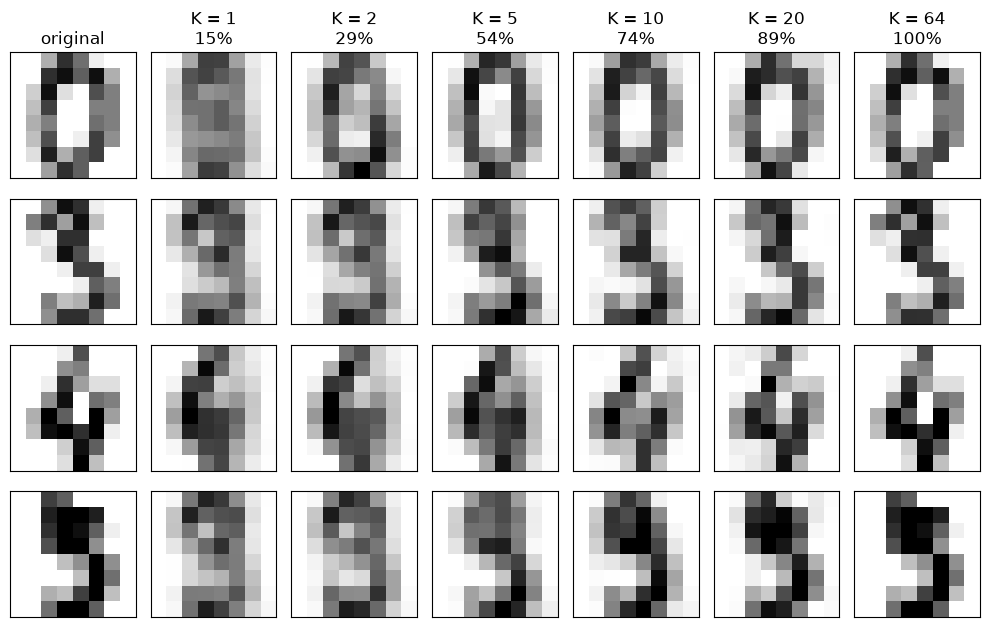

In [ ]:
Ks = [1, 2, 5, 10, 20, 64]
examples = [0, 3, 4, 5]                                     # four images of the dataset
fig, axes = plt.subplots(len(examples), len(Ks) + 1, figsize=(10, 6.5))
for row, i in enumerate(examples):
    axes[row, 0].imshow(digits.data[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[row, 0].set_title("original" if row == 0 else "")
    for col, K in enumerate(Ks, start=1):
        p = PCA(n_components=K).fit(digits.data)
        rebuilt = p.inverse_transform(p.transform(digits.data[i:i + 1]))
        axes[row, col].imshow(rebuilt.reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
        if row == 0:
            axes[row, col].set_title(f"K = {K}\n{cumulative[K - 1]:.0%}")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.show()

**What this shows:** with 1 or 2 components every image looks like a blurry "average digit". With 10 components (74% of the variance) most digits are recognisable, and with 20 (89%) they are close to the originals. With all 64 components the reconstruction is exact.

## The whole process

![The four steps of PCA: 1, centre the data (and standardise if the units differ); 2, compute the covariance matrix; 3, find its eigenvectors and sort them by eigenvalue; 4, project the data on the first K eigenvectors.](../img/pca_steps.png)

In practice, scikit-learn does not build the covariance matrix: it uses the **singular value decomposition** (SVD) of the centred data, $X_c = U\Sigma V^\top$. The rows of $V^\top$ are the same components and the eigenvalues are $\sigma_k^2/(n-1)$; this is faster and more accurate numerically. You will meet the SVD again in the topic modeling section.

## Summary

| Strengths | Limits |
|---|---|
| Removes redundancy: the new variables are uncorrelated | Information is lost if you drop too many components |
| Few components can keep most of the variance | A component mixes all the variables: harder to interpret |
| Makes high-dimensional data easy to draw | Only numeric variables, and only **linear** combinations |
| Fewer variables: faster models, less noise, less overfitting | Sensitive to the scale of the variables (standardise first) and to outliers |

To remember:

* PCA finds the **axes along which the data varies the most**. Each one is perpendicular to the previous ones.
* These axes are the **eigenvectors** of the covariance matrix; the **eigenvalues** are the variances along them.
* In the new axes, the covariance matrix is **diagonal**: the components are uncorrelated.
* The **explained variance ratio** tells how much information each component keeps, and helps to choose how many to keep.
* `inverse_transform` goes back to the original variables; the error is the variance of the dropped components.

::: {.sb-next}
**[Next: PCA with scikit-learn →](../lessons/workflow.ipynb)**
:::